In [2]:
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 3)
RANDOM_STATE = 42

DATA_PATH = Path("cardio_cleaned.csv")
TARGET = "cardio"
NUMERIC_FEATURES = ["age_years","height","weight","ap_hi","ap_lo","bmi"]
CATEGORICAL_FEATURES = ["gender", "cholesterol","gluc","smoke","alco","active"]
ID_COLUMNS = ["id"] if "id" in pd.read_csv(DATA_PATH, nrows=0).columns else []
DATETIME_COLUMNS = []
EXCLUDED_COLUMNS = ["age"] if "age" in pd.read_csv(DATA_PATH, nrows=0).columns else []
TARGET_LABELS = { 0: "No cardiovascular disease", 1: "Cardiovascular disease"}
POSITIVE_CLASS = 1

ORDERED_FEATURE = "age_years"
ORDERED_EDGES = [20, 30, 40, 50, 60, 70]
INTERACTION_FEATURES = ("age_years", "weight")
CATEGORICAL_PAIR = ("gender", "cholesterol")
PLACEHOLDER_VALUES = {}

MAX_SCATTER_ROWS = 6000
MIN_GROUP_SIZE = 30

In [3]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File not found: {DATA_PATH}. "
        "Make sure cardio_cleaned.csv is in the same folder as this notebook."
    )

raw = pd.read_csv(DATA_PATH)

print(f"Loaded {DATA_PATH.name}: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())
raw.info()

Loaded cardio_cleaned.csv: 68,666 rows × 14 columns


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi
0,18393,2,168.0,62.0,110,80,1,1,0,0,1,0,50.4,21.97
1,20228,1,156.0,85.0,140,90,3,1,0,0,1,1,55.4,34.93
2,18857,1,165.0,64.0,130,70,3,1,0,0,0,1,51.6,23.51
3,17623,2,169.0,82.0,150,100,1,1,0,0,1,1,48.2,28.71
4,17474,1,156.0,56.0,100,60,1,1,0,0,0,0,47.8,23.01


<class 'pandas.DataFrame'>
RangeIndex: 68666 entries, 0 to 68665
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          68666 non-null  int64  
 1   gender       68666 non-null  int64  
 2   height       68639 non-null  float64
 3   weight       68660 non-null  float64
 4   ap_hi        68666 non-null  int64  
 5   ap_lo        68666 non-null  int64  
 6   cholesterol  68666 non-null  int64  
 7   gluc         68666 non-null  int64  
 8   smoke        68666 non-null  int64  
 9   alco         68666 non-null  int64  
 10  active       68666 non-null  int64  
 11  cardio       68666 non-null  int64  
 12  age_years    68666 non-null  float64
 13  bmi          68633 non-null  float64
dtypes: float64(4), int64(10)
memory usage: 7.3 MB


In [4]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_n": raw.isna().sum(),
    "unique_nonmissing": raw.nunique(),
    "examples": [", ".join(map(str, raw[c].dropna().unique()[:5])) for c in raw.columns]
})
display(profile)


roles = {"target": [TARGET], "numerical": NUMERIC_FEATURES,
         "categorical": CATEGORICAL_FEATURES, "ID": ID_COLUMNS,
         "datetime": DATETIME_COLUMNS, "excluded": EXCLUDED_COLUMNS}
assigned = [c for cols in roles.values() for c in cols]
assert len(assigned) == len(set(assigned)), "A column has more than one role."
assert set(assigned) == set(raw.columns), "Review missing, extra, or unassigned column names."
assert all(pd.api.types.is_numeric_dtype(raw[c]) for c in NUMERIC_FEATURES), "Review numeric parsing."
assert not raw.empty, "The dataset has no rows."
display(pd.DataFrame([(c, role) for role, cols in roles.items() for c in cols],
                     columns=["column", "analysis_role"]))

,dtype,missing_n,unique_nonmissing,examples
age,int64,0,8065,"18393, 20228, 18857, 17623, 17474"
gender,int64,0,2,"2, 1"
height,float64,27,85,"168.0, 156.0, 165.0, 169.0, 151.0"
weight,float64,6,275,"62.0, 85.0, 64.0, 82.0, 56.0"
ap_hi,int64,0,106,"110, 140, 130, 150, 100"
ap_lo,int64,0,78,"80, 90, 70, 100, 60"
cholesterol,int64,0,3,"1, 3, 2"
gluc,int64,0,3,"1, 2, 3"
smoke,int64,0,2,"0, 1"
alco,int64,0,2,"0, 1"


,column,analysis_role
0,cardio,target
1,age_years,numerical
2,height,numerical
3,weight,numerical
4,ap_hi,numerical
5,ap_lo,numerical
6,bmi,numerical
7,gender,categorical
8,cholesterol,categorical
9,gluc,categorical


,missing_n,missing_pct
bmi,33,0.048
height,27,0.039
weight,6,0.009
gender,0,0.000
ap_hi,0,0.000
age,0,0.000
ap_lo,0,0.000
cholesterol,0,0.000
smoke,0,0.000
gluc,0,0.000


Repeated rows beyond the first identical row: 24
Constant/all-missing columns: []


""


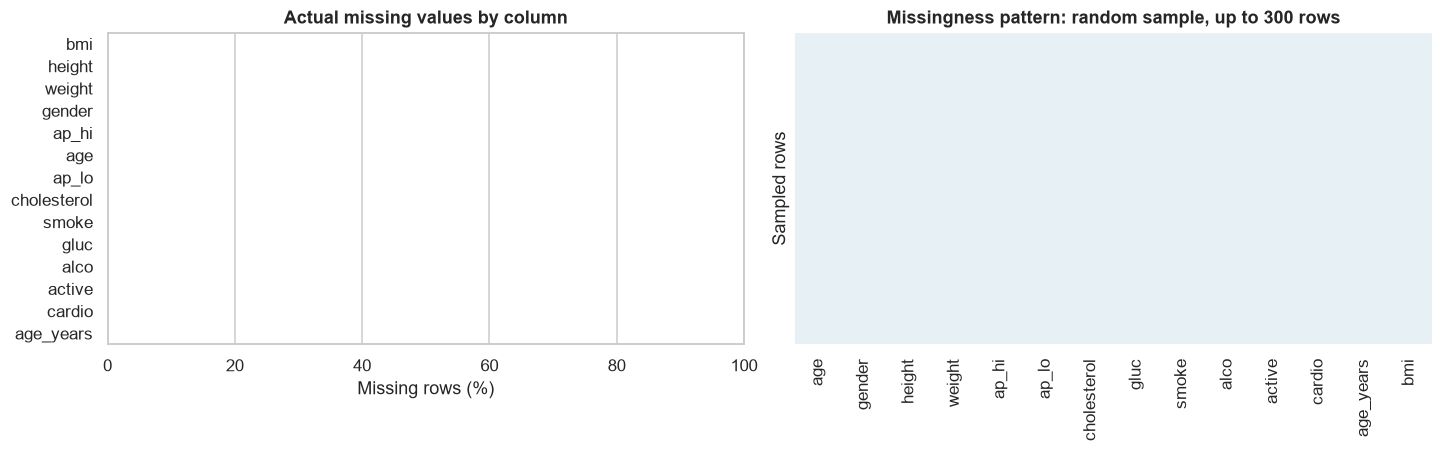

In [5]:
missing = raw.isna().sum().sort_values(ascending=False)
quality = pd.DataFrame({"missing_n": missing, "missing_pct": missing / len(raw) * 100})
display(quality)
print(f"Repeated rows beyond the first identical row: {raw.duplicated().sum():,}")
print("Constant/all-missing columns:", raw.columns[raw.nunique(dropna=True) <= 1].tolist())

placeholder_rows = []
for col, values in PLACEHOLDER_VALUES.items():
    if col in raw:
        for value in values:
            n = int(raw[col].eq(value).sum())
            placeholder_rows.append({"column": col, "recorded_value": value,
                                     "rows": n, "percent": 100 * n / len(raw)})
display(pd.DataFrame(placeholder_rows))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
missing_pct = quality["missing_pct"].rename_axis("column").reset_index()
sns.barplot(data=missing_pct, x="missing_pct", y="column", color="#3783a5", ax=axes[0])
axes[0].set(title="Actual missing values by column", xlabel="Missing rows (%)", ylabel="")
axes[0].set_xlim(0, 100)
if missing.sum() == 0:
    axes[0].text(0.5, 0.5, "All columns: 0% actual missing", transform=axes[0].transAxes,
                 ha="center", bbox={"facecolor":"white", "alpha":0.9})
    axes[1].axis("off")
    axes[1].text(0.05, 0.6, "No actual missing values to map.\nText placeholders are audited separately.",
                 transform=axes[1].transAxes)
else:
    missing_sample = raw.sample(min(300, len(raw)), random_state=RANDOM_STATE)
    sns.heatmap(missing_sample.isna(), cbar=False, yticklabels=False, ax=axes[1],
                cmap=["#e7f0f5", "#ce5d45"], vmin=0, vmax=1)
    axes[1].set(title="Missingness pattern: random sample, up to 300 rows", ylabel="Sampled rows")
plt.show()

In [6]:
for col in CATEGORICAL_FEATURES:
    print(f"\n{col}")
    display(raw[col].value_counts(dropna=False).rename("rows").to_frame())

if NUMERIC_FEATURES:
    display(raw[NUMERIC_FEATURES].describe().T)
    display(pd.DataFrame({
        "most_frequent_value": [raw[c].mode().iloc[0] if not raw[c].mode().empty else np.nan
                                for c in NUMERIC_FEATURES],
        "frequency_pct": [100 * raw[c].value_counts(normalize=True).iloc[0]
                          if raw[c].notna().any() else np.nan for c in NUMERIC_FEATURES]
    }, index=NUMERIC_FEATURES))


gender


,rows
gender,
1,44727
2,23939



cholesterol


,rows
cholesterol,
1,51497
2,9300
3,7869



gluc


...

,rows
alco,
0,65002
1,3664



active


,rows
active,
1,55164
0,13502


,count,mean,std,min,25%,50%,75%,max
age_years,68666.0,53.291,6.758,29.60,48.30,53.90,58.40,64.90
height,68639.0,164.394,7.978,100.00,159.00,165.00,170.00,207.00
weight,68660.0,74.122,14.324,30.00,65.00,72.00,82.00,200.00
ap_hi,68666.0,126.670,16.681,70.00,120.00,120.00,140.00,240.00
ap_lo,68666.0,81.301,9.423,40.00,80.00,80.00,90.00,150.00
bmi,68633.0,27.473,5.351,10.73,23.88,26.35,30.12,152.55


,most_frequent_value,frequency_pct
age_years,56.00,1.095
height,165.00,8.383
weight,65.00,5.523
ap_hi,120.00,40.282
ap_lo,80.00,50.587
bmi,23.88,1.667


In [7]:
print(f"Rows excluded from class comparisons because target is missing: {raw[TARGET].isna().sum():,}")
df = raw.loc[raw[TARGET].notna()].copy()
assert not df.empty, "No labeled rows remain."
if NUMERIC_FEATURES:
    assert not np.isinf(df[NUMERIC_FEATURES].to_numpy(dtype=float)).any(), "Investigate infinite values."
    NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if df[c].notna().any()]
    print("Numerical features with at least one observed value:", NUMERIC_FEATURES)

observed_classes = sorted(df[TARGET].unique(), key=str)
label_lookup = {value: str(TARGET_LABELS.get(value, value))for value in observed_classes}

assert len(set(label_lookup.values())) == len(label_lookup), "Target display labels must be distinct."
CLASS_COL = "__target_label__"
assert CLASS_COL not in df.columns
df[CLASS_COL] = df[TARGET].map(label_lookup)
class_order = [label_lookup[v] for v in observed_classes]
class_colors = dict(zip(class_order, sns.color_palette("colorblind", len(class_order))))
IS_BINARY = len(observed_classes) == 2 and POSITIVE_CLASS in observed_classes

for col in CATEGORICAL_FEATURES:
    df[col] = df[col].astype("string").fillna("<Missing>")
category_orders = {c: df[c].value_counts().index.tolist() for c in CATEGORICAL_FEATURES}
print(f"Analysis population: {len(df):,} rows; classes: {class_order}")


Rows excluded from class comparisons because target is missing: 0
Numerical features with at least one observed value: ['age_years', 'height', 'weight', 'ap_hi', 'ap_lo', 'bmi']
Analysis population: 68,666 rows; classes: ['No cardiovascular disease', 'Cardiovascular disease']


In [8]:
categorical_columns = CATEGORICAL_FEATURES.copy()
numerical_columns = NUMERIC_FEATURES.copy()
class_col = CLASS_COL

def subplot_grid(n, ncols=2, width=6, height=4):
    """Return a figure and n usable axes; hide any unused panels."""
    ncols = min(ncols, max(1, n))
    nrows = int(np.ceil(max(1, n) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows),
                             squeeze=False, constrained_layout=True)
    flat = axes.ravel()
    for ax in flat[n:]:
        ax.set_visible(False)
    return fig, flat[:n]

def label_bars(ax, fmt="%.1f"):
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, fontsize=8, padding=3)
    ax.margins(y=0.18)

In [9]:
target_counts = df[CLASS_COL].value_counts().reindex(class_order)
target_summary = pd.DataFrame({"rows": target_counts, "percent": target_counts/len(df)*100})
print(target_counts)
print(target_summary)

__target_label__
No cardiovascular disease    34697
Cardiovascular disease       33969
Name: count, dtype: int64
                            rows  percent
__target_label__                         
No cardiovascular disease  34697    50.53
Cardiovascular disease     33969    49.47


C:\Users\mg050\AppData\Local\Temp\ipykernel_13780\658464438.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=CLASS_COL, order=class_order, palette=class_colors,


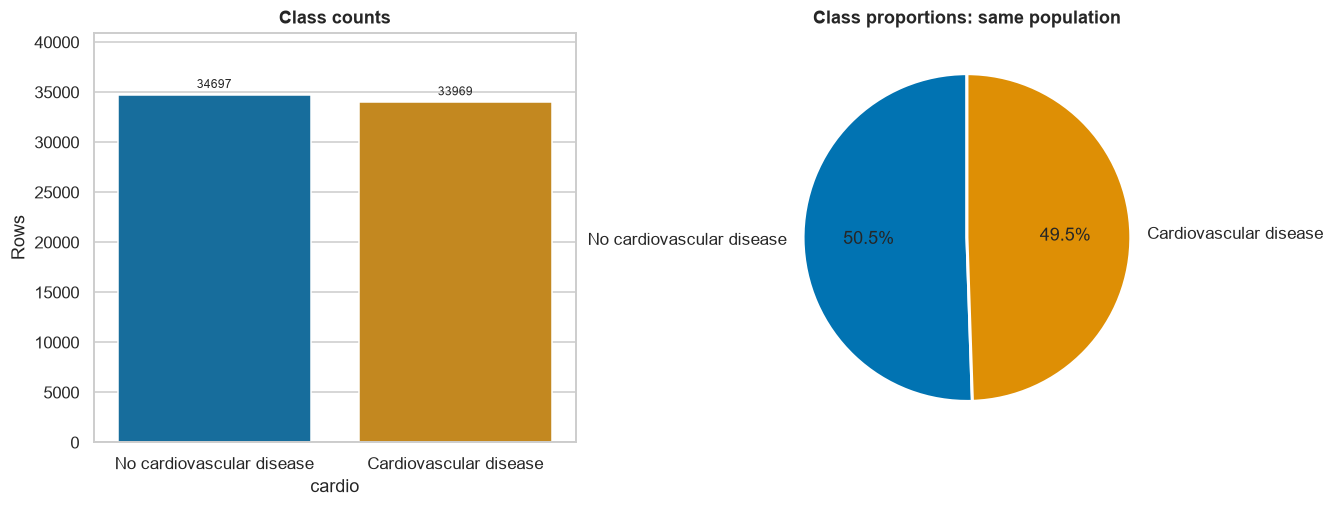

Majority-class baseline on these rows: 50.53%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
sns.countplot(data=df, x=CLASS_COL, order=class_order, palette=class_colors,
              legend=False, ax=axes[0])
axes[0].set(title="Class counts", xlabel=TARGET, ylabel="Rows")
label_bars(axes[0], "%.0f")
if len(class_order) <= 5:
    axes[1].pie(target_counts, labels=class_order, autopct="%1.1f%%", startangle=90,
                colors=[class_colors[c] for c in class_order],
                wedgeprops={"edgecolor":"white", "linewidth":2})
    axes[1].set_title("Class proportions: same population")
else:
    axes[1].axis("off")
    axes[1].text(0, 0.5, "Pie omitted: use the countplot and percentage table for many classes.")
plt.show()
print(f"Majority-class baseline on these rows: {target_counts.max()/len(df):.2%}")

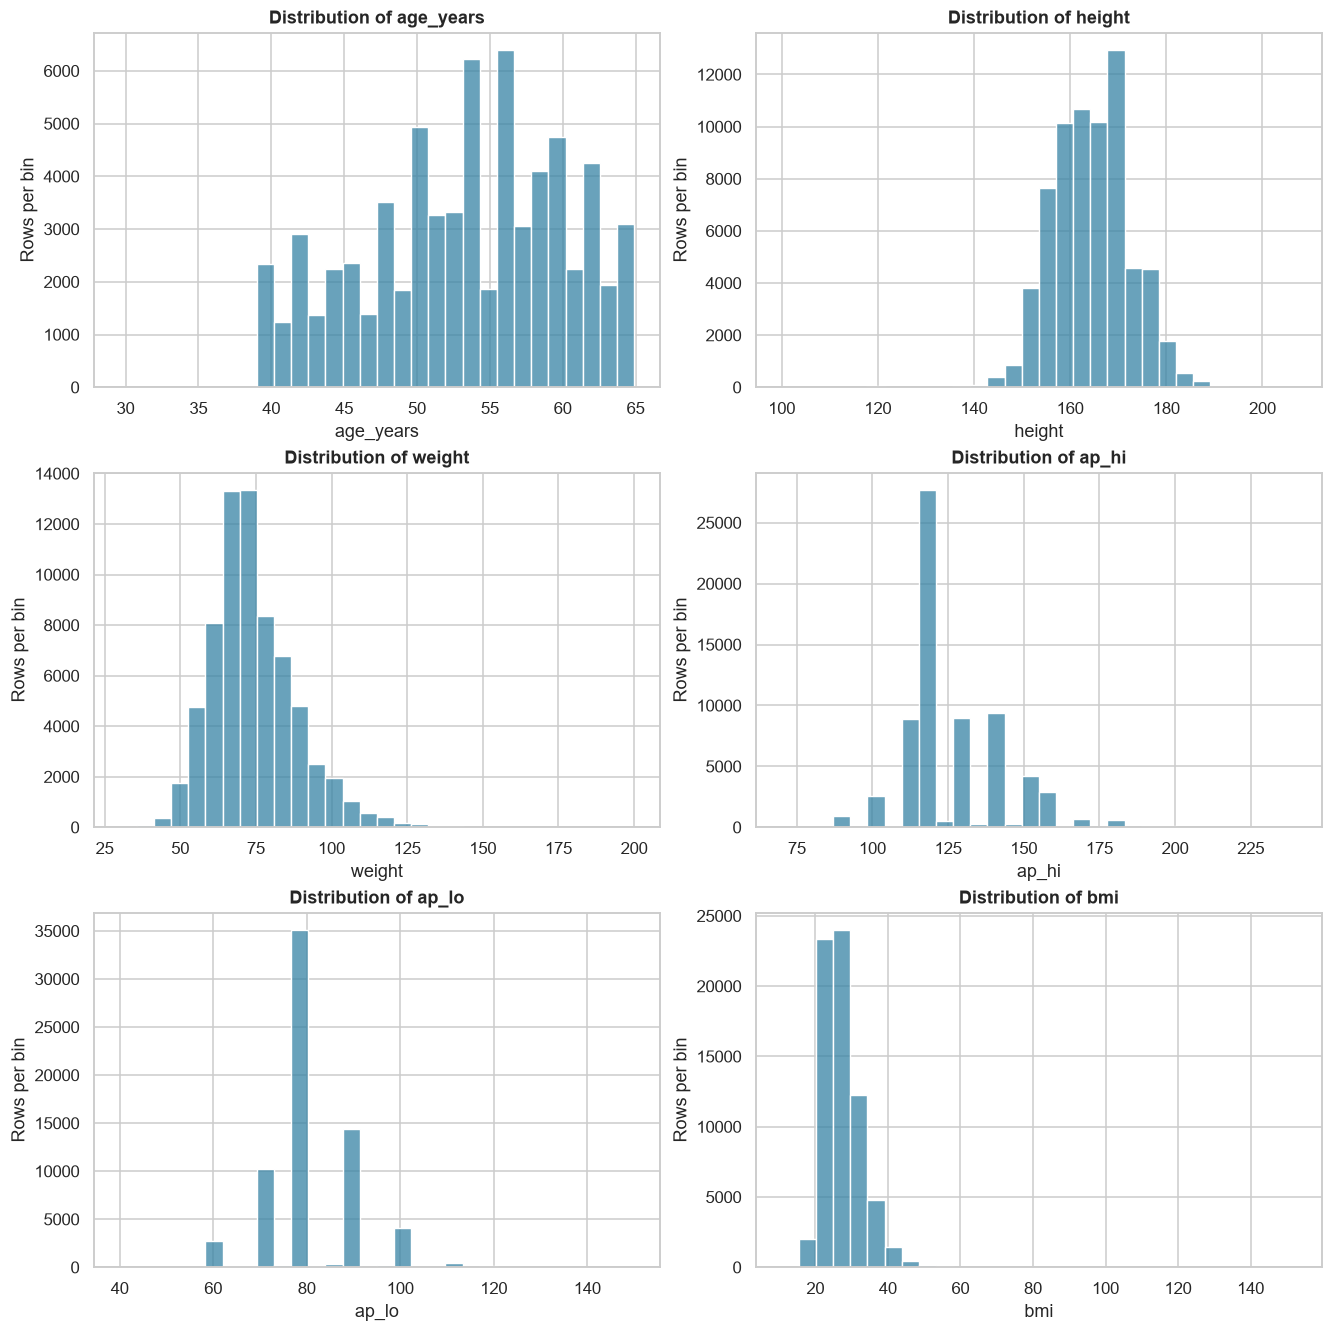

In [11]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(data=df, x=col, bins=30, color="#3783a5", ax=ax)
        ax.set(title=f"Distribution of {col}", ylabel="Rows per bin")
    plt.show()

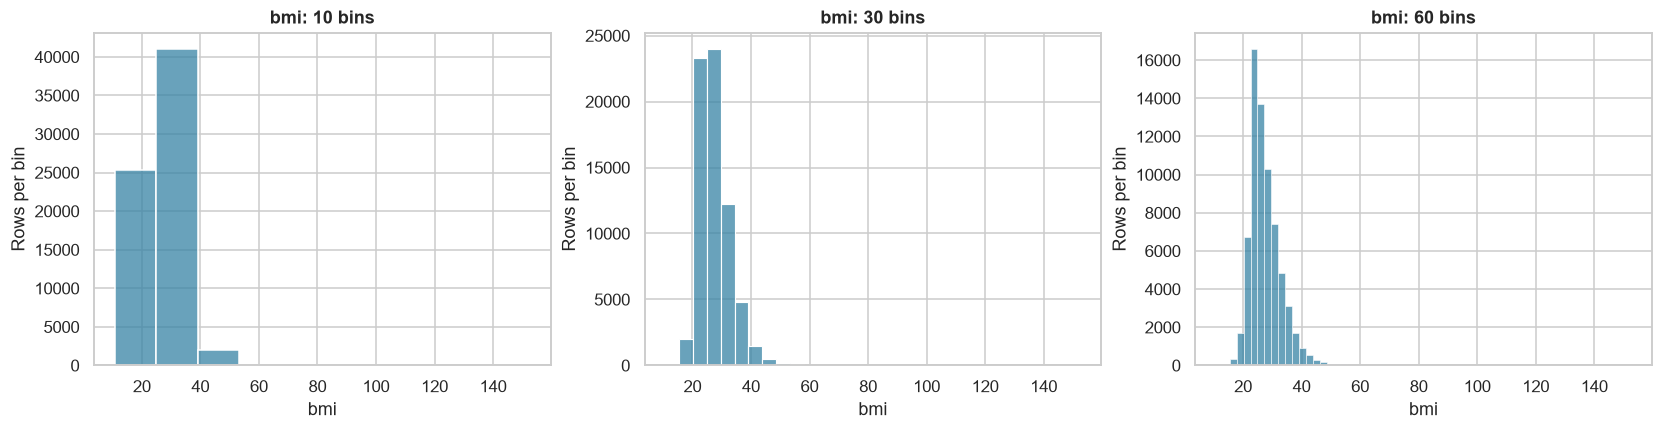

In [12]:
if NUMERIC_FEATURES:
    example_feature = "bmi" if "bmi" in NUMERIC_FEATURES else NUMERIC_FEATURES[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True, constrained_layout=True)
    for ax, bins in zip(axes, [10, 30, 60]):
        sns.histplot(data=df, x=example_feature, bins=bins, color="#3783a5", ax=ax)
        ax.set(title=f"{example_feature}: {bins} bins", ylabel="Rows per bin")
    plt.show()

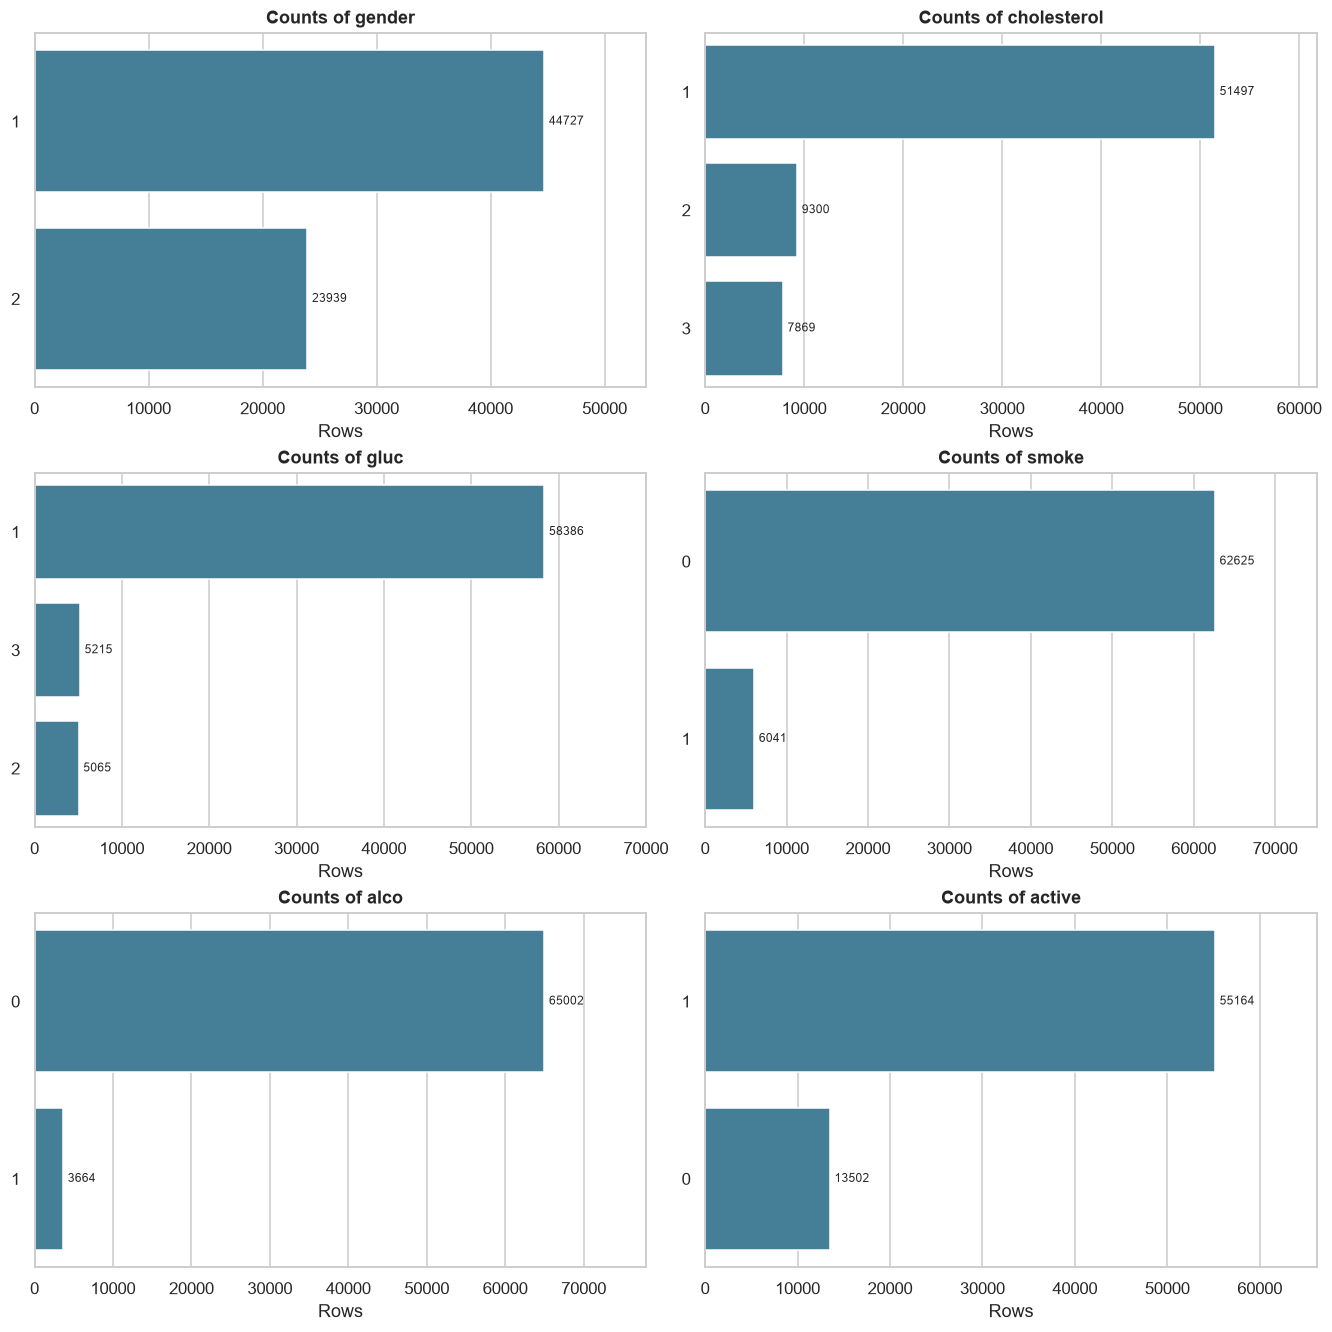

In [13]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES))
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, y=col, order=category_orders[col], color="#3783a5", ax=ax)
        ax.set(title=f"Counts of {col}", xlabel="Rows", ylabel="")
        for container in ax.containers:
            ax.bar_label(container, fmt="%.0f", fontsize=8, padding=3)
        ax.margins(x=0.2)
    plt.show()

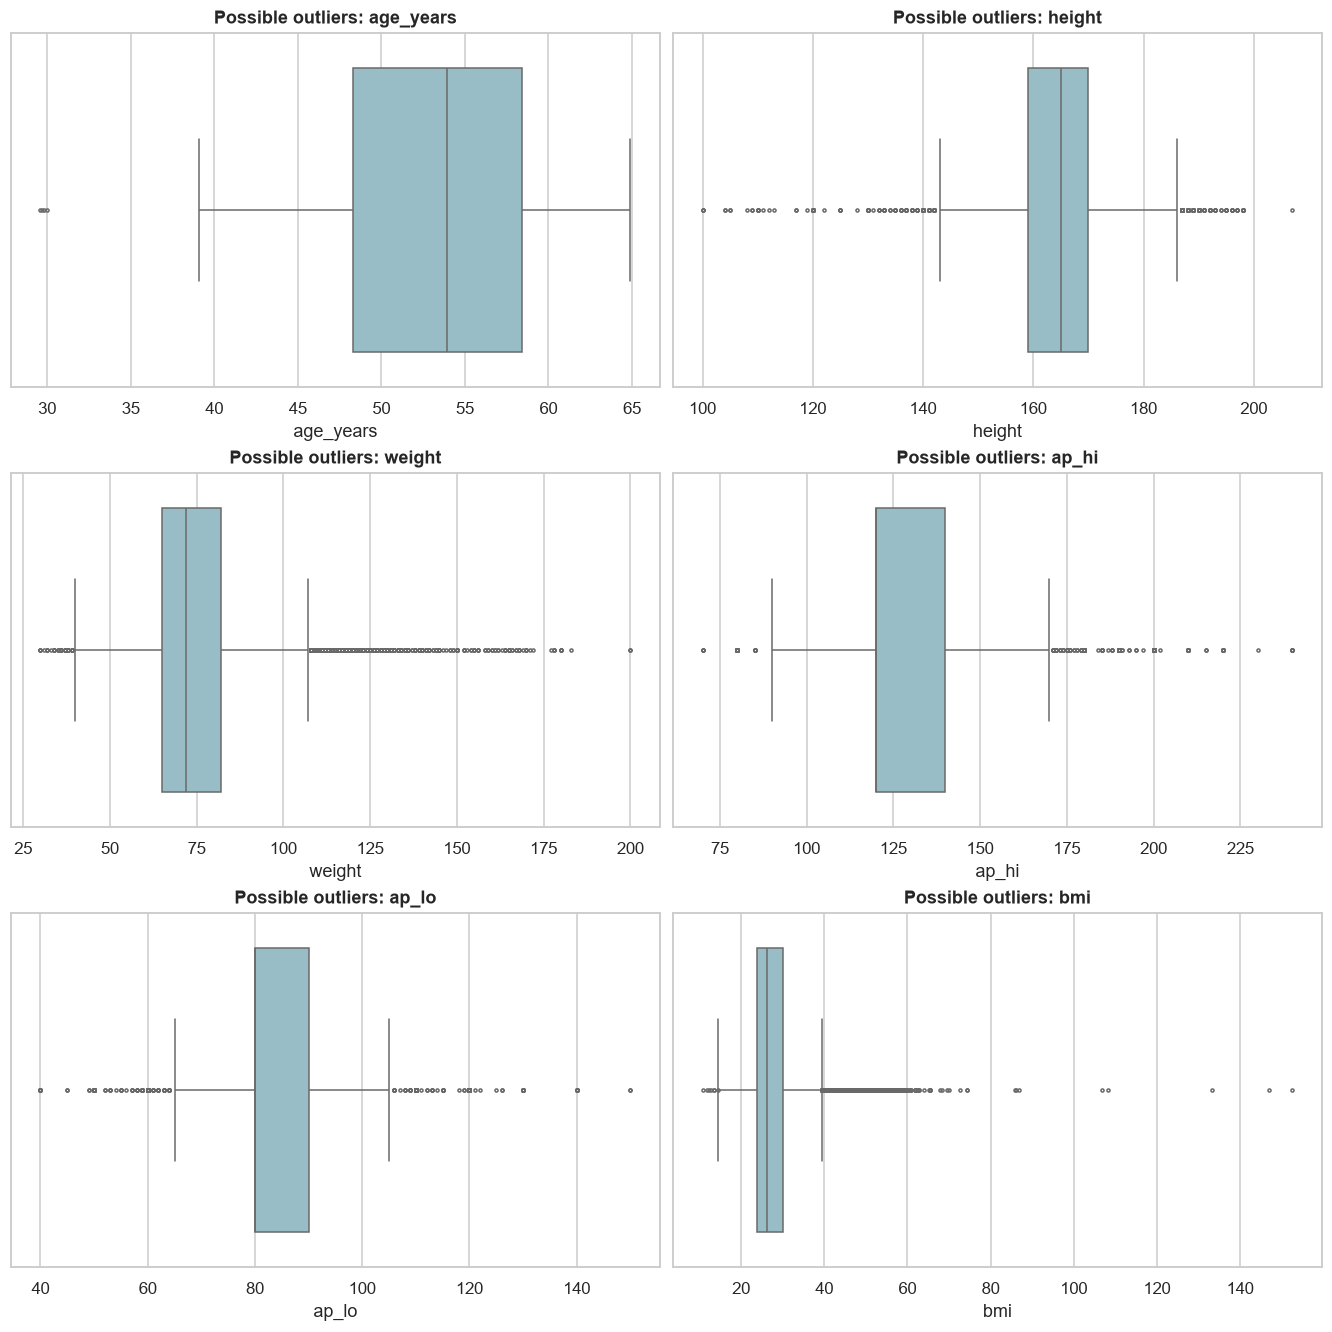

,feature,Q1,Q3,IQR,lower_fence,upper_fence,flagged_n,observed_n,flagged_pct
0,age_years,48.30,58.40,10.10,33.15,73.55,4,68666,0.006
1,height,159.00,170.00,11.00,142.50,186.50,478,68639,0.696
2,weight,65.00,82.00,17.00,39.50,107.50,1739,68660,2.533
3,ap_hi,120.00,140.00,20.00,90.00,170.00,1005,68666,1.464
4,ap_lo,80.00,90.00,10.00,65.00,105.00,3499,68666,5.096
5,bmi,23.88,30.12,6.24,14.52,39.48,1992,68633,2.902


Flagged rows have been retained.


In [14]:
outlier_rows = []
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(data=df, x=col, color="#91c2ce", fliersize=2, ax=ax)
        ax.set_title(f"Possible outliers: {col}")
        x = df[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
        flagged = (x < lower) | (x > upper)
        outlier_rows.append({"feature": col, "Q1": q1, "Q3": q3, "IQR": iqr,
                             "lower_fence": lower, "upper_fence": upper,
                             "flagged_n": int(flagged.sum()), "observed_n": len(x),
                             "flagged_pct": flagged.mean()*100})
    plt.show()
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)
print("Flagged rows have been retained.")


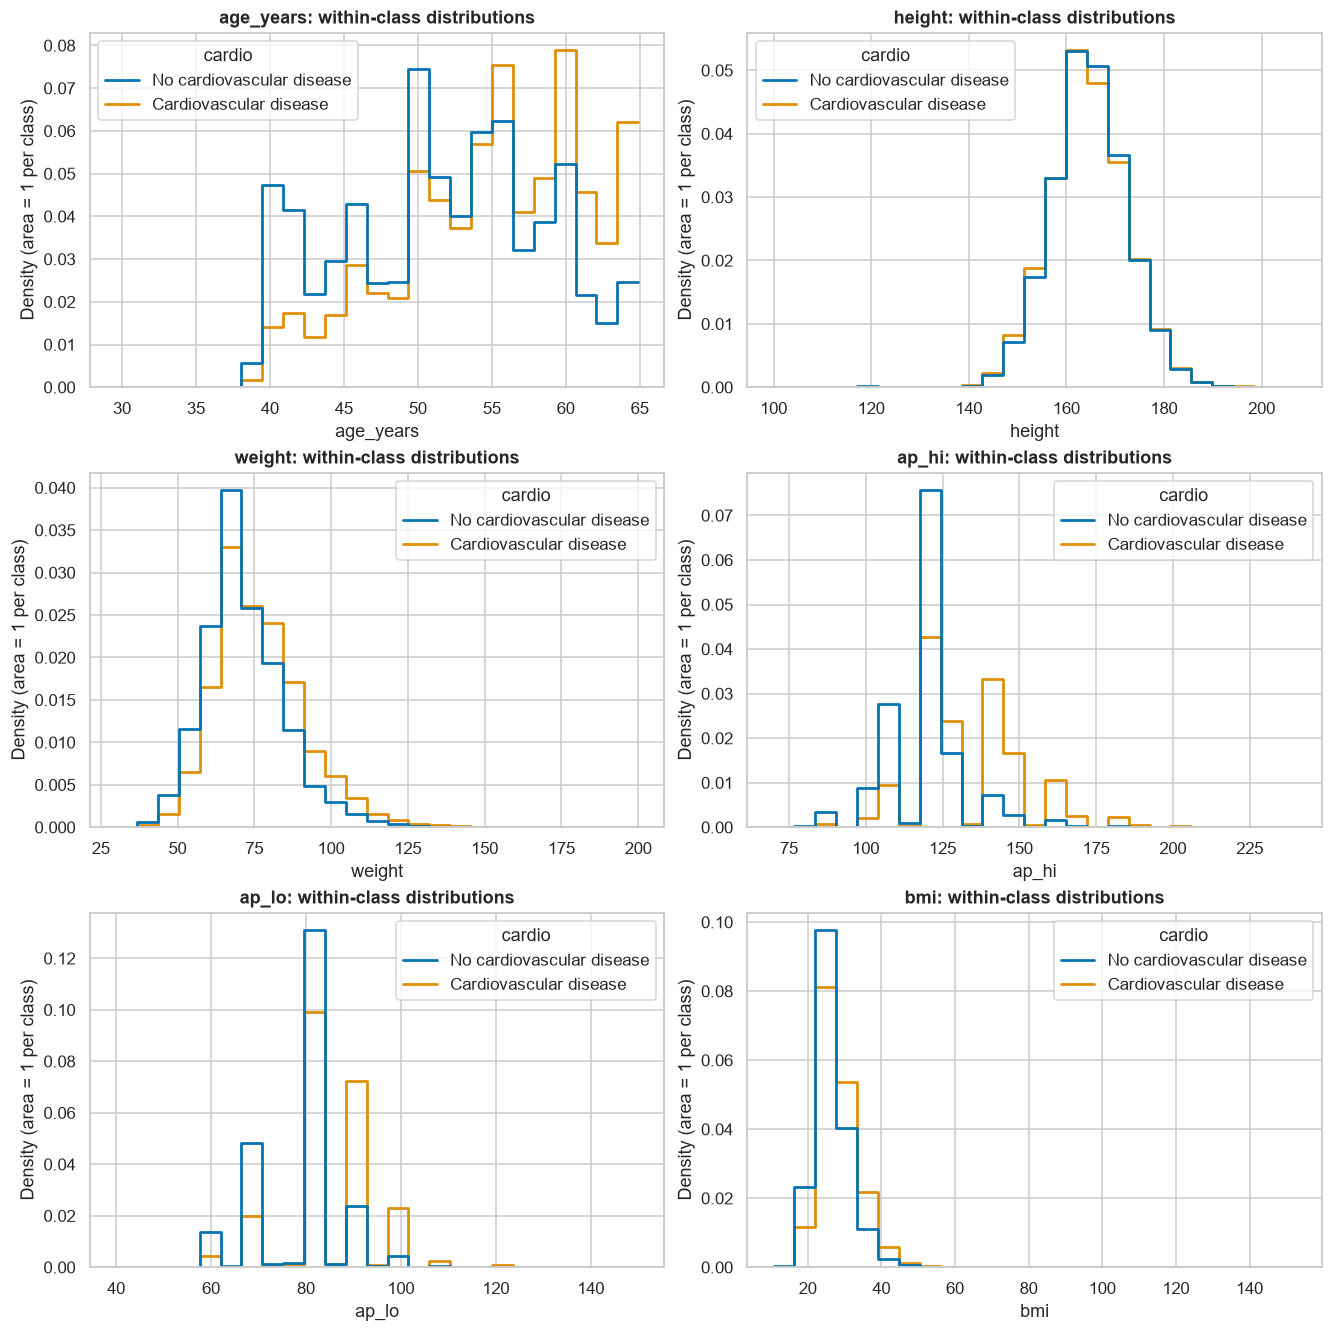

In [15]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.histplot(data=df, x=col, hue=CLASS_COL, hue_order=class_order,
                     palette=class_colors, bins=25, stat="density", common_norm=False,
                     common_bins=True, element="step", fill=False, linewidth=1.8, ax=ax)
        ax.set(title=f"{col}: within-class distributions", ylabel="Density (area = 1 per class)")
        if ax.get_legend() is not None:
            ax.get_legend().set_title(TARGET)
    plt.show()

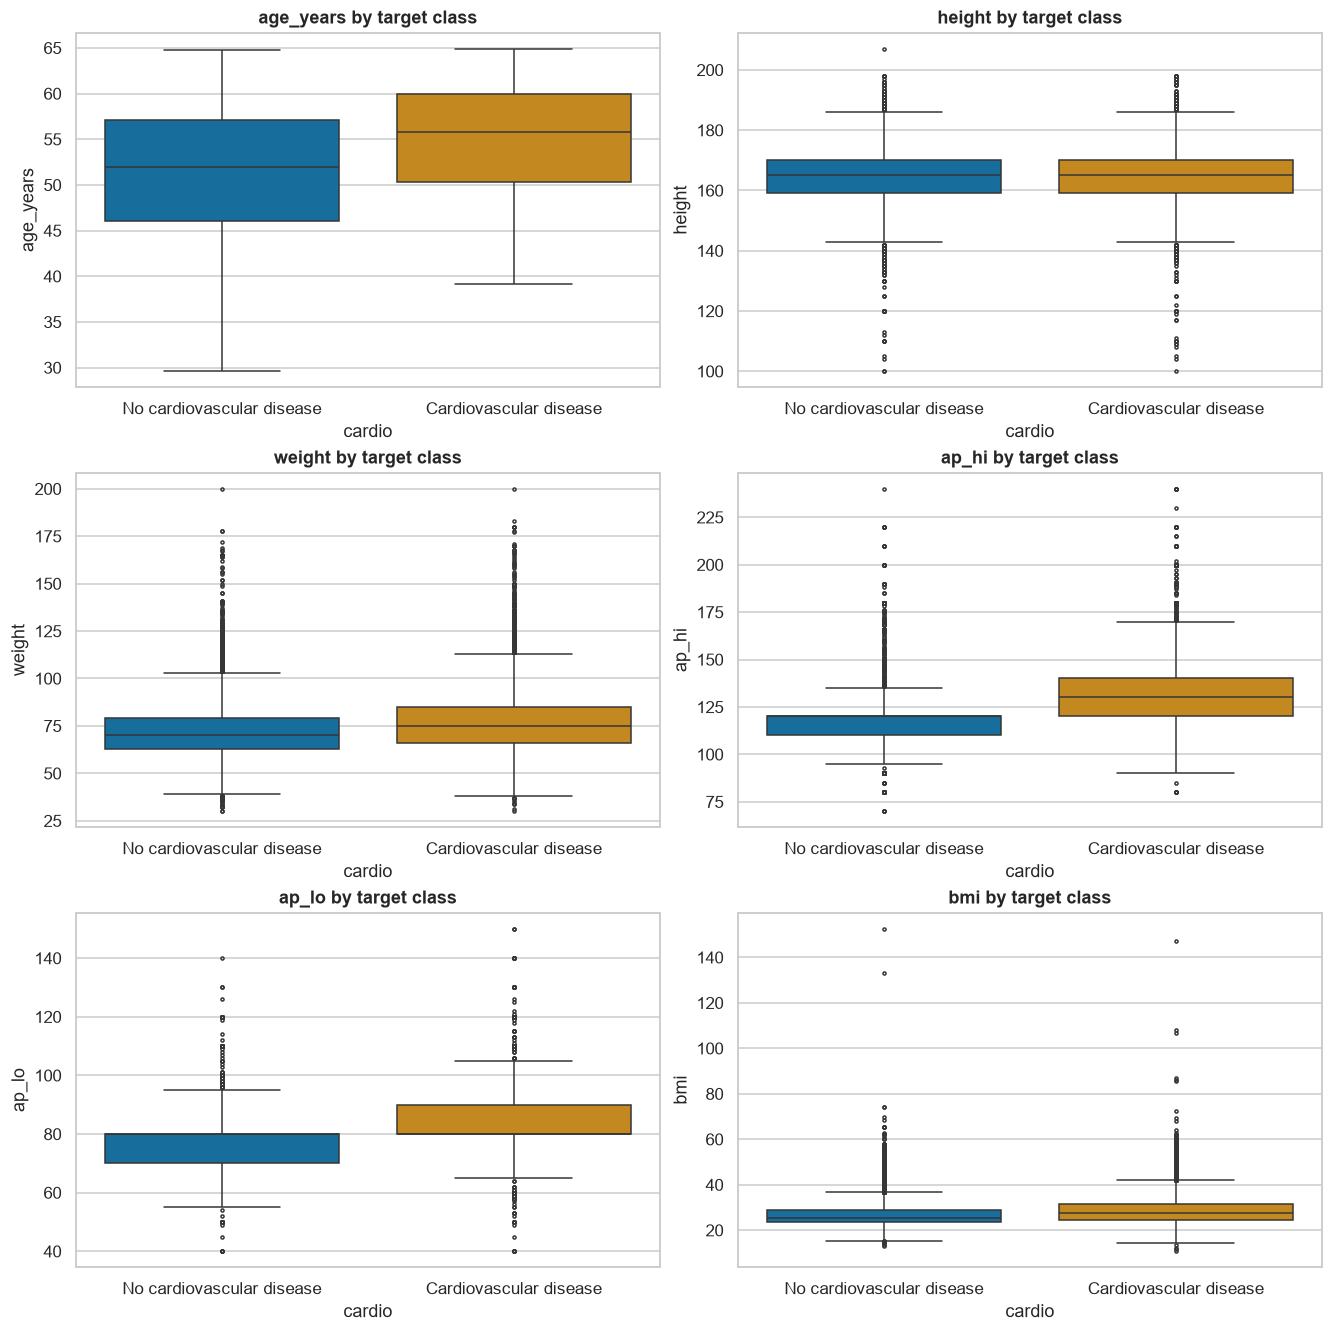

In [16]:
if NUMERIC_FEATURES:
    fig, axes = subplot_grid(len(NUMERIC_FEATURES))
    for ax, col in zip(axes, NUMERIC_FEATURES):
        sns.boxplot(
            data=df, x=CLASS_COL, y=col,
            order=class_order, hue=CLASS_COL,
            palette=class_colors, legend=False,
            fliersize=2, ax=ax
        )
        ax.set(title=f"{col} by target class", xlabel=TARGET)

    plt.show()

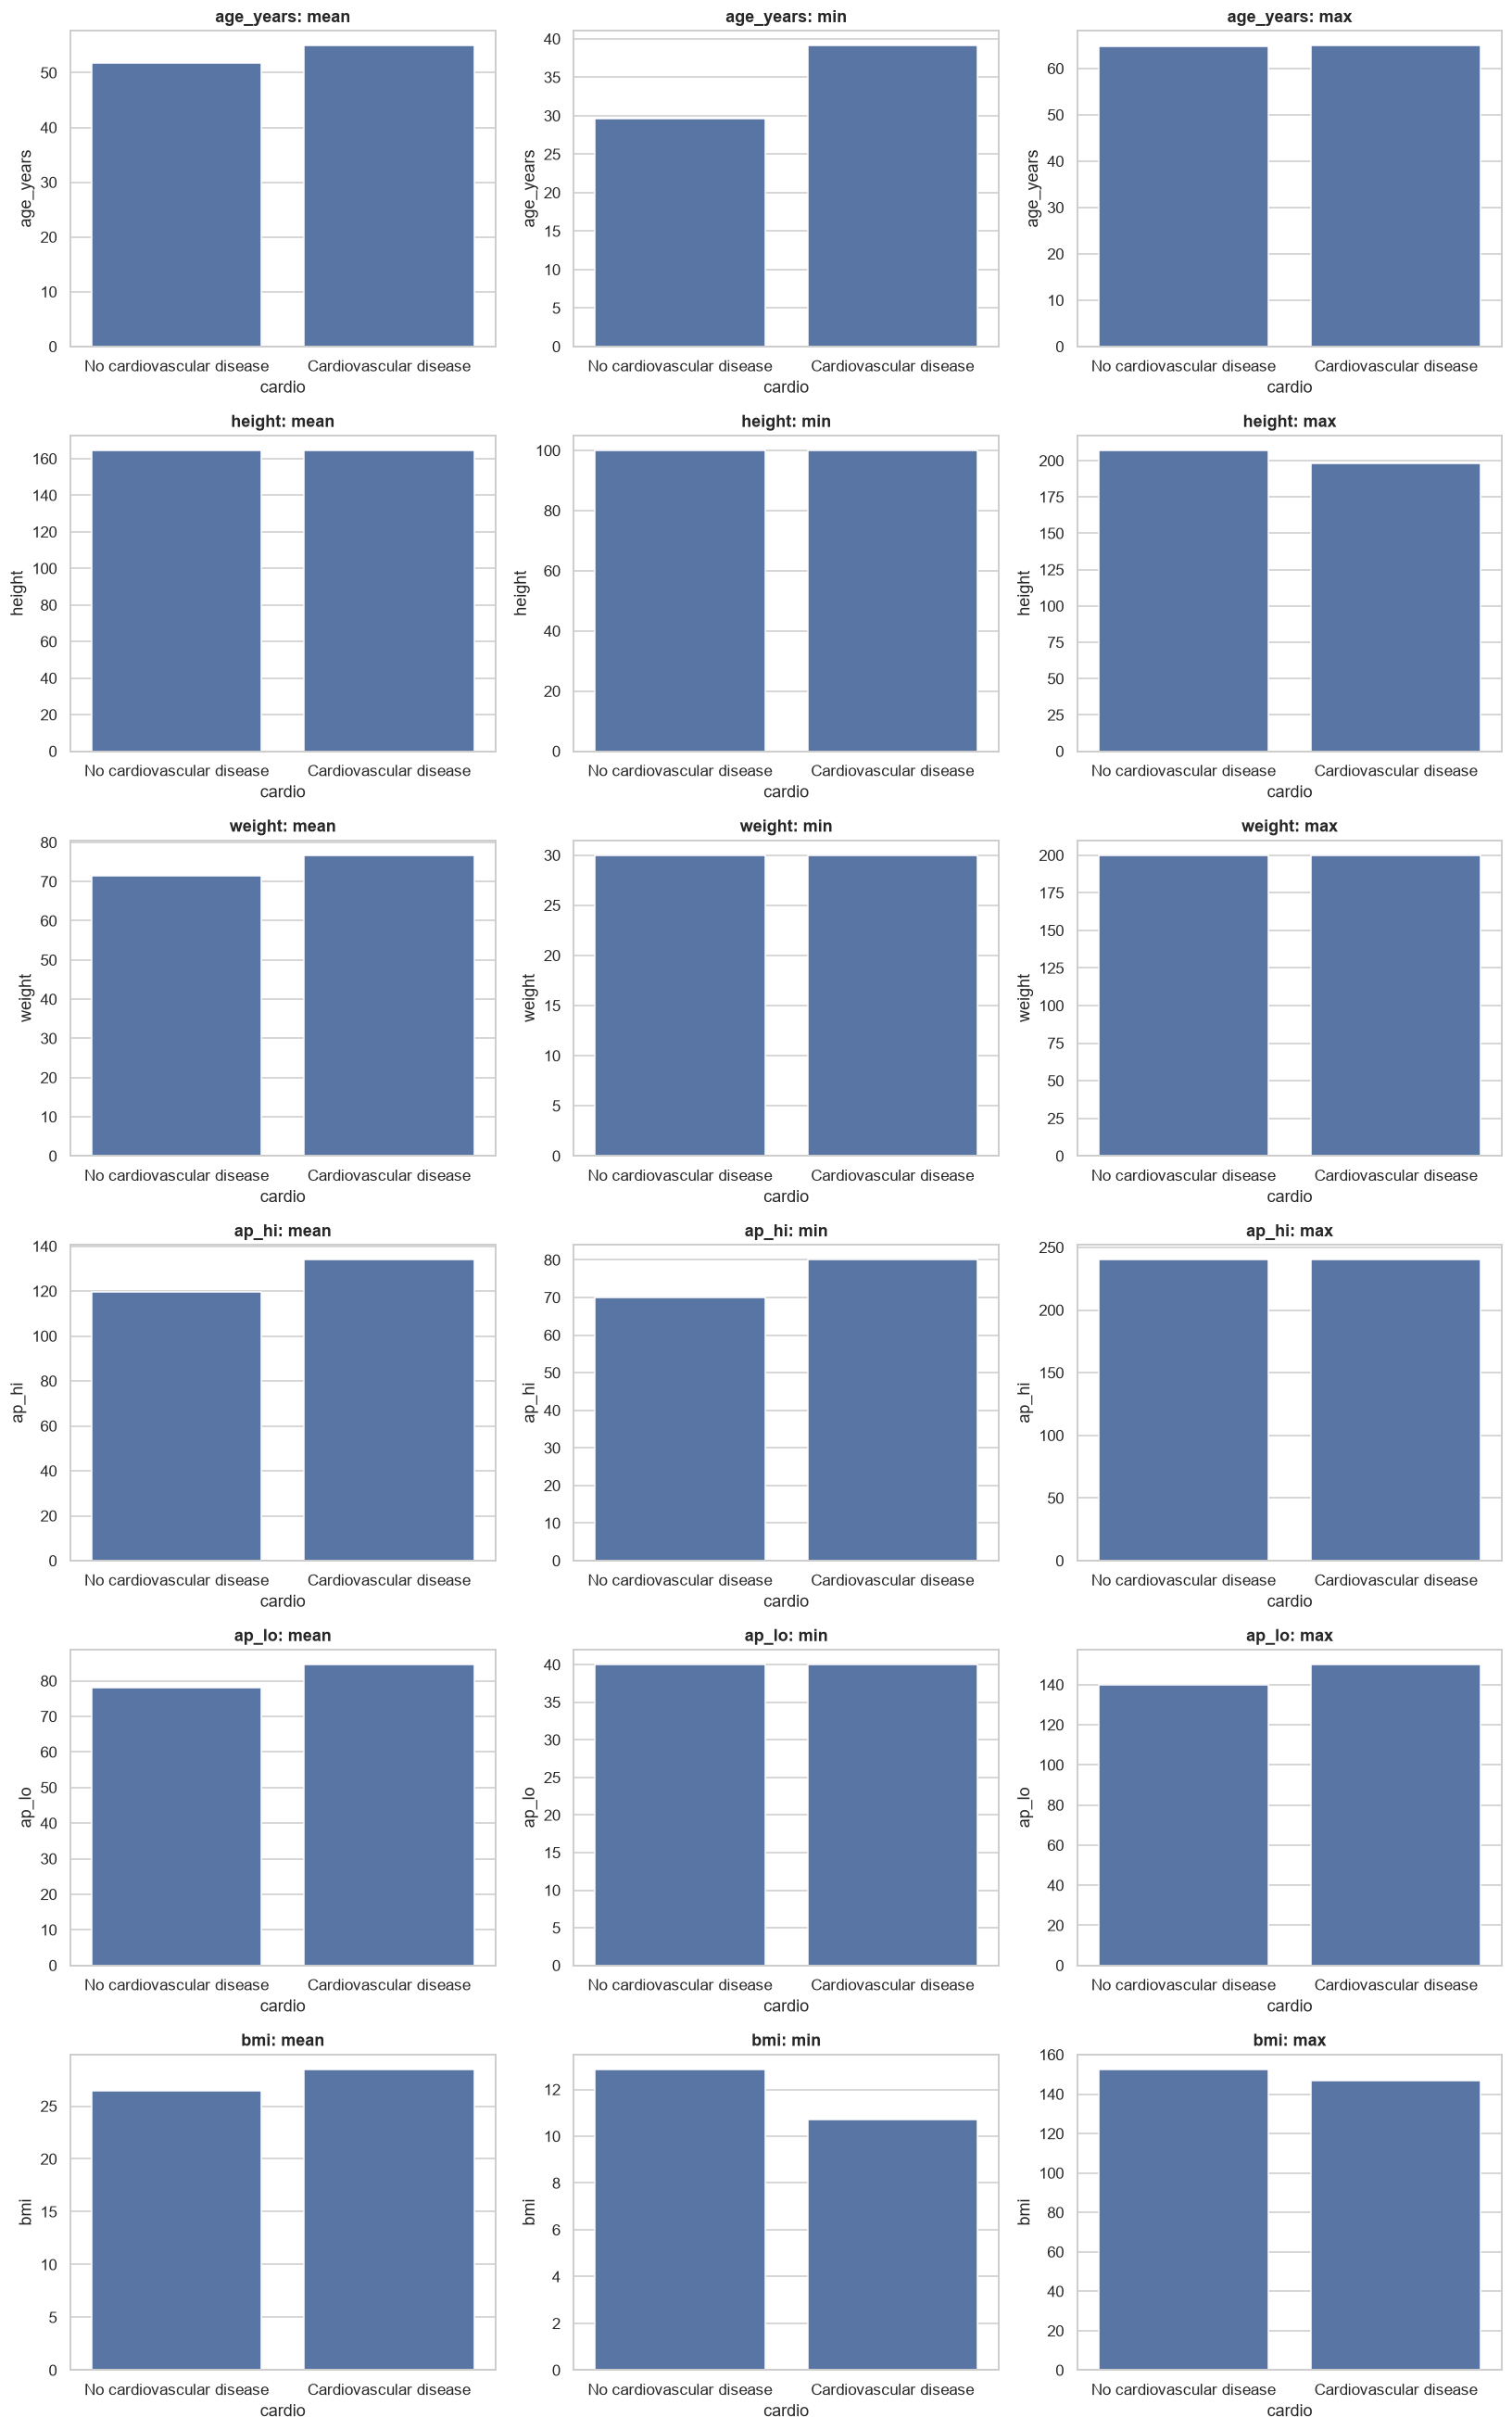

In [17]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:

        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)

        sns.barplot(
            data=df,
            x=CLASS_COL,
            y=column,
            estimator=statistic,
            errorbar=None
        )

        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)
        plot_number += 1

plt.tight_layout()
plt.show()

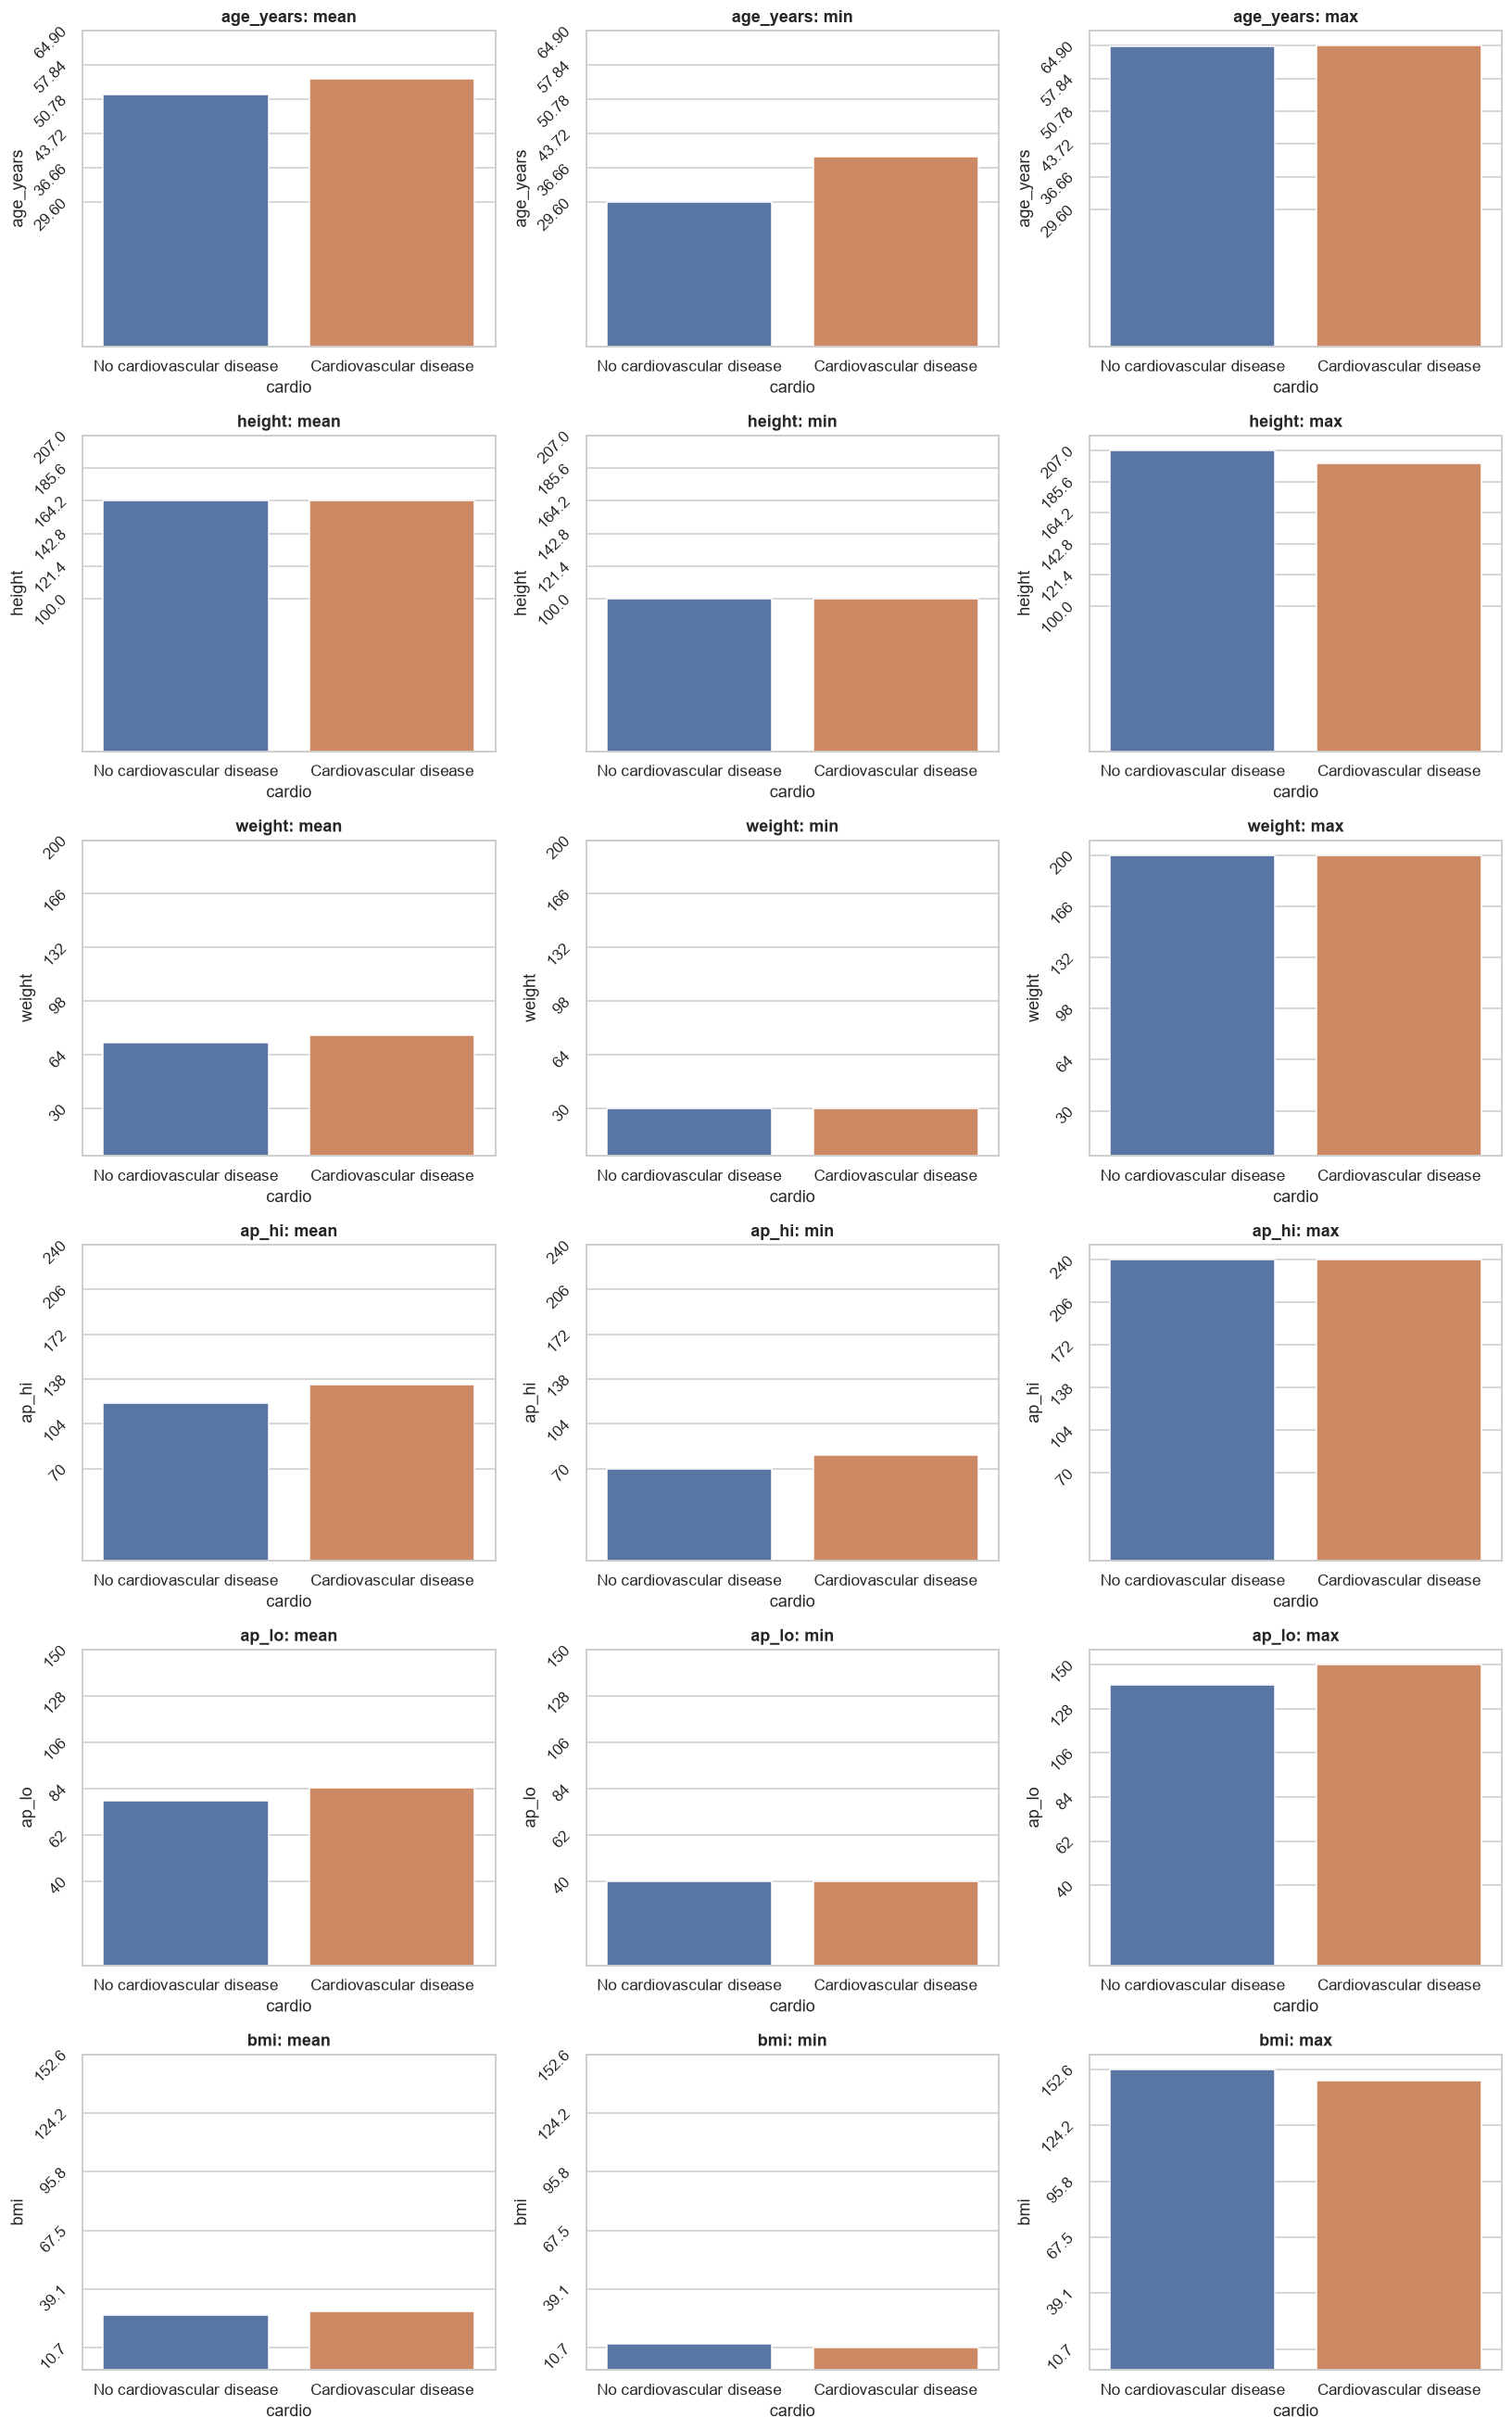

In [18]:
statistics = ["mean", "min", "max"]

plt.figure(figsize=(15, 4 * len(NUMERIC_FEATURES)))

plot_number = 1

for column in NUMERIC_FEATURES:
    for statistic in statistics:

        plt.subplot(len(NUMERIC_FEATURES), 3, plot_number)

        min_value = df[column].min()
        max_value = df[column].max()

        sns.barplot(
            data=df,
            x=CLASS_COL,
            y=column,
            hue=CLASS_COL,
            estimator=statistic,
            errorbar=None,
            legend=False
        )

        plt.title(f"{column}: {statistic}")
        plt.xlabel(TARGET)

        plt.yticks(np.linspace(min_value, max_value, 6), rotation=45)

        plot_number += 1

plt.tight_layout()
plt.show()

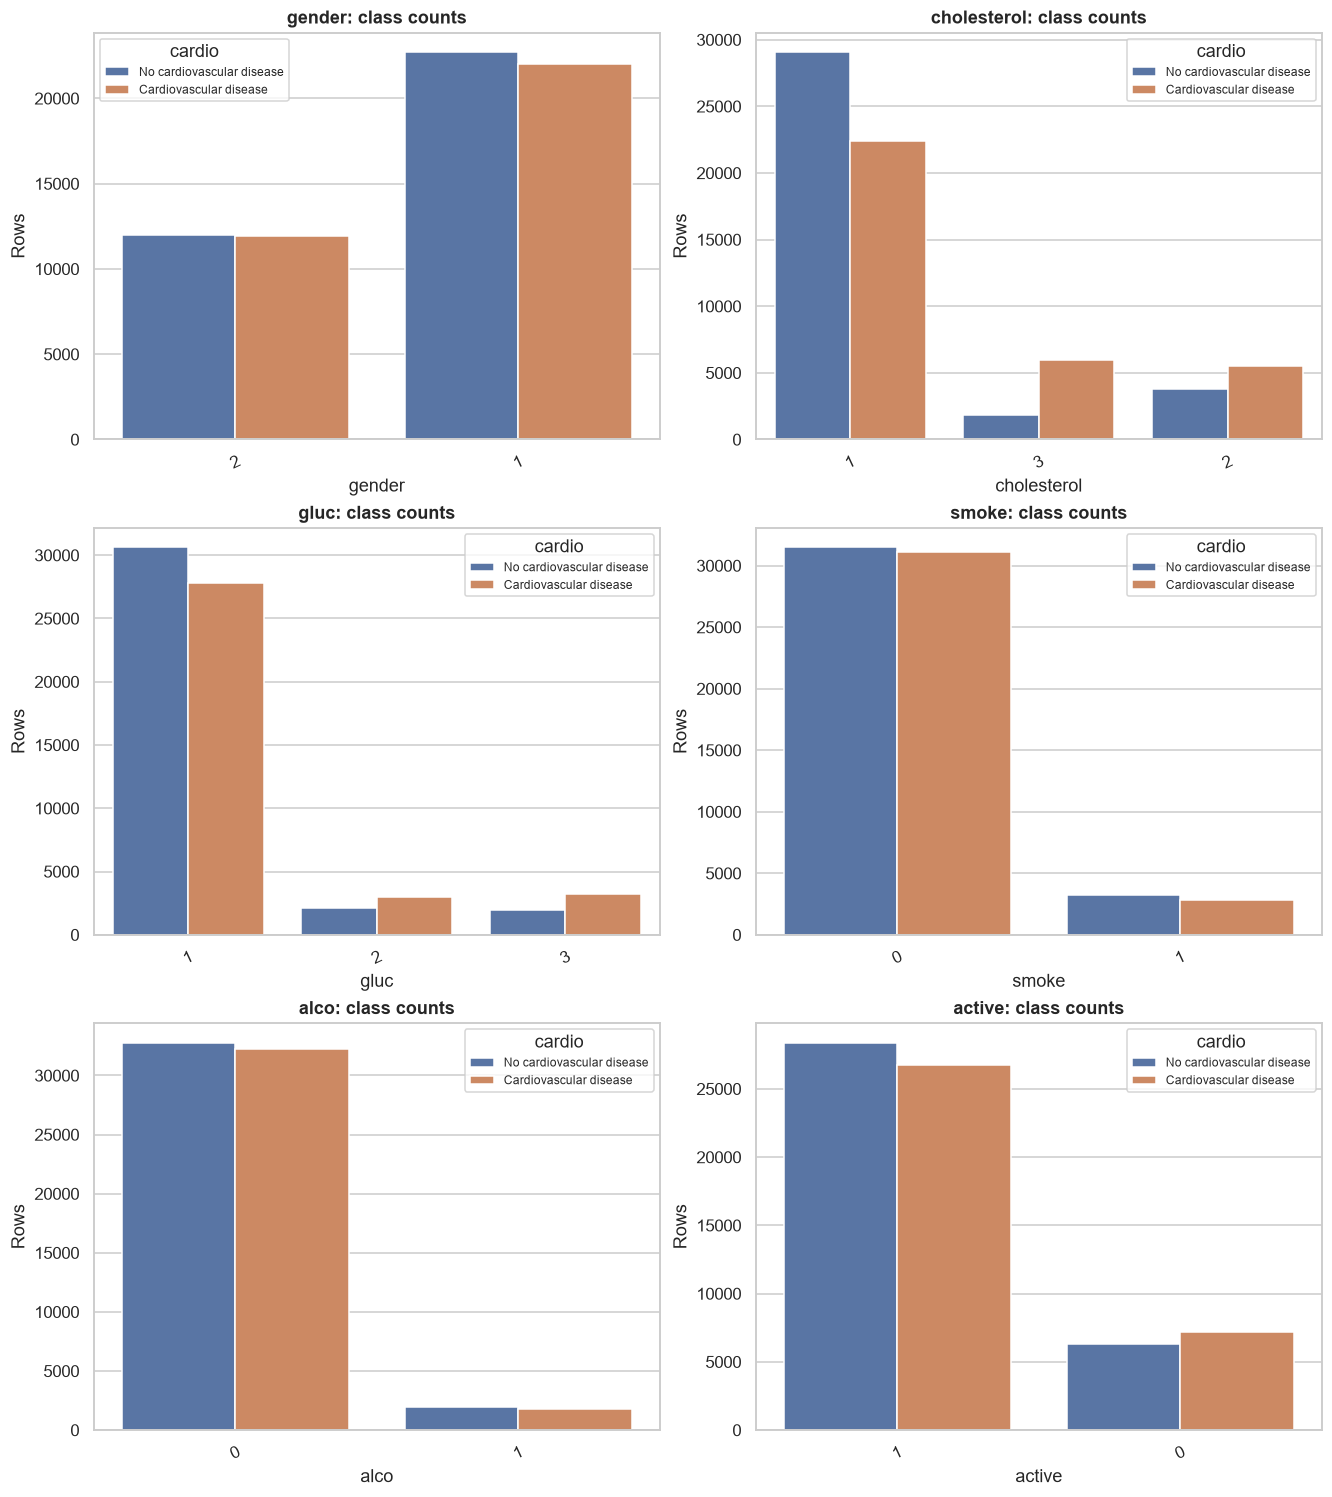

In [19]:
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.5)
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        sns.countplot(data=df, x=col, hue=CLASS_COL, ax=ax)
        # , order=category_orders[col],
        # hue_order=class_order, palette=class_colors,
        ax.set(title=f"{col}: class counts", ylabel="Rows")
        ax.tick_params(axis="x", rotation=25)
        ax.legend(title=TARGET, fontsize=8)
    plt.show()


gender: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
gender,,,,
1,50.79,49.21,44727,False
2,50.05,49.95,23939,False



cholesterol: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
cholesterol,,,,
1,56.46,43.54,51497,False
2,40.37,59.63,9300,False
3,23.74,76.26,7869,False



gluc: percentages within each category


...

__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
smoke,,,,
0,50.28,49.72,62625,False
1,53.15,46.85,6041,False



alco: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
alco,,,,
0,50.43,49.57,65002,False
1,52.37,47.63,3664,False



active: percentages within each category


__target_label__,No cardiovascular disease,Cardiovascular disease,n,small_group
active,,,,
1,51.46,48.54,55164,False
0,46.75,53.25,13502,False


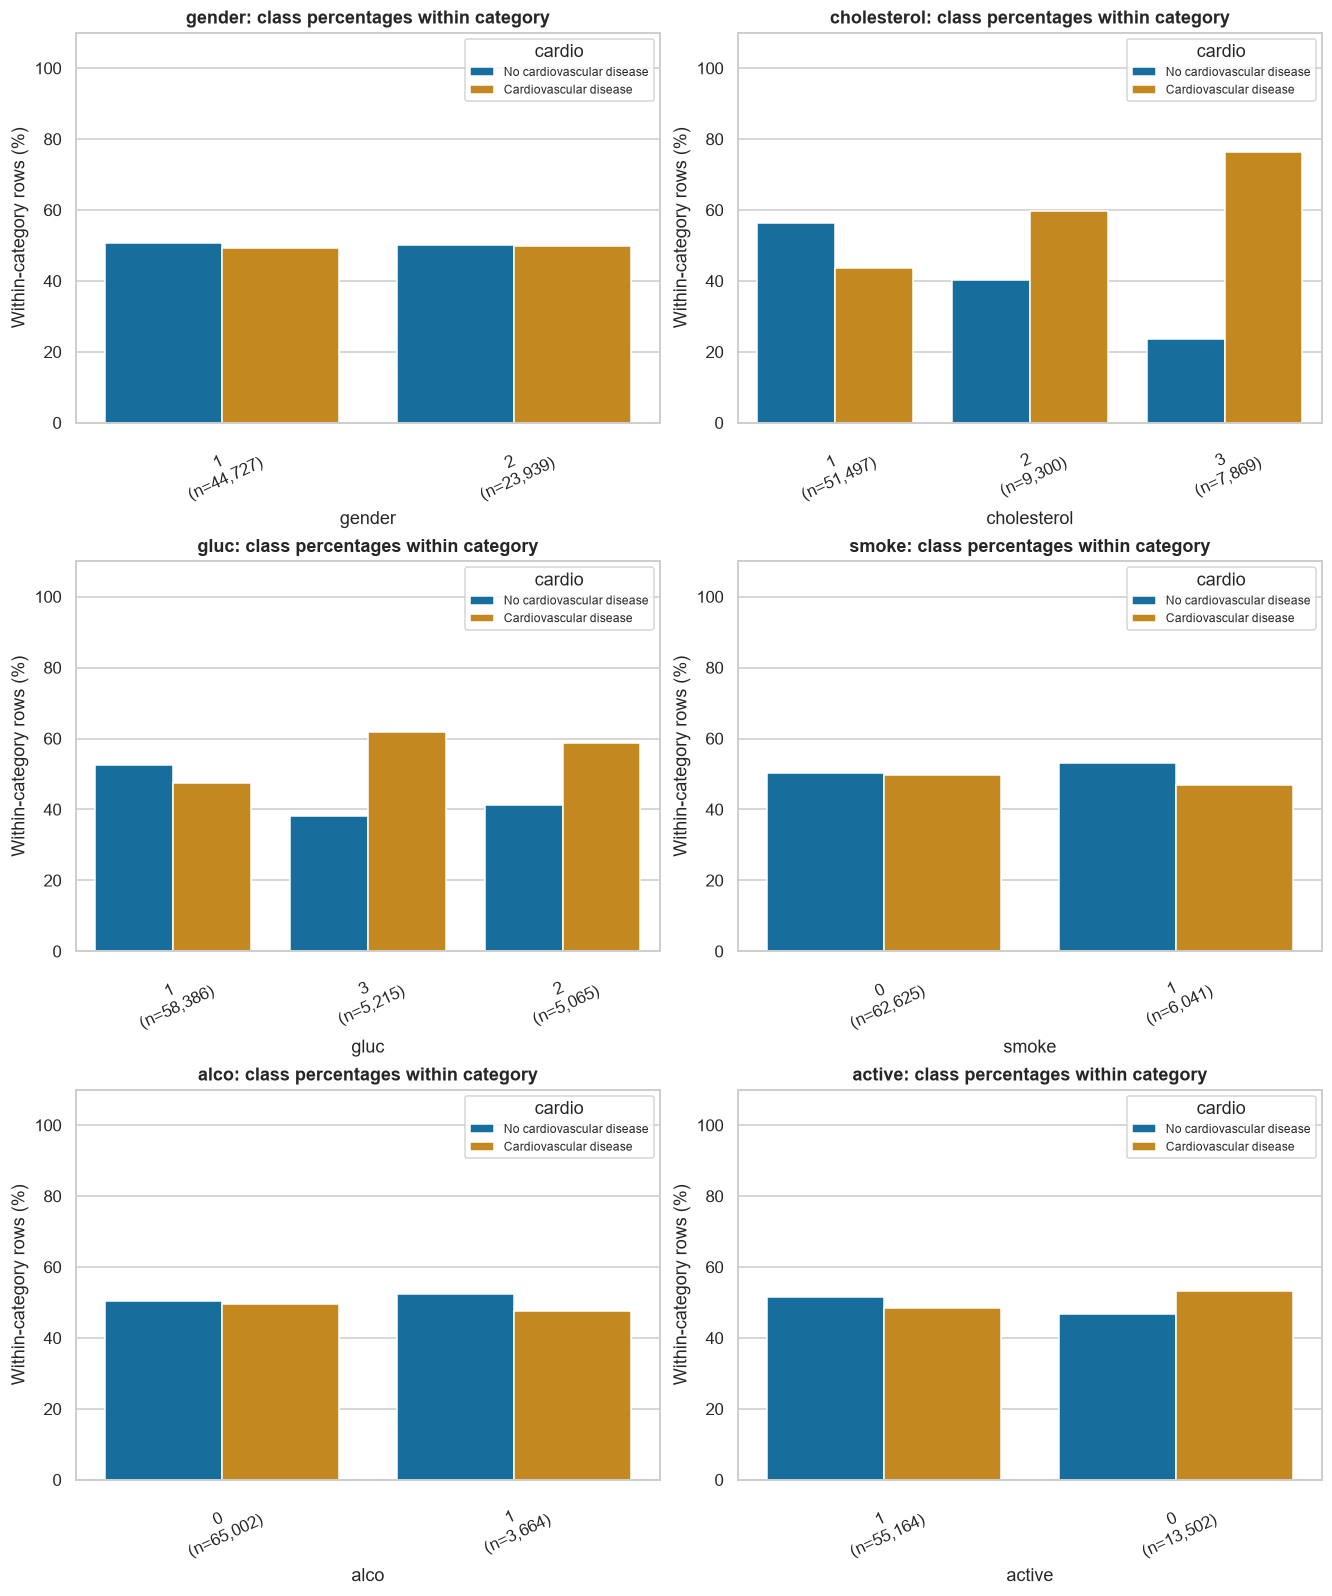

In [20]:
category_tables = {}
if CATEGORICAL_FEATURES:
    fig, axes = subplot_grid(len(CATEGORICAL_FEATURES), height=4.8)
    for ax, col in zip(axes, CATEGORICAL_FEATURES):
        counts = pd.crosstab(df[col], df[CLASS_COL]).reindex(
            index=category_orders[col], columns=class_order, fill_value=0)
        support = counts.sum(axis=1)
        percentages = counts.div(support, axis=0) * 100
        category_tables[col] = (counts, percentages)
        print(f"\n{col}: percentages within each category")
        display(percentages.round(2).assign(n=support, small_group=support < MIN_GROUP_SIZE))

        plot_rates = percentages.rename_axis(index="category", columns="target_class").reset_index()
        plot_rates = plot_rates.melt(id_vars="category", var_name="target_class", value_name="percent")
        sns.barplot(data=plot_rates, x="category", y="percent", hue="target_class",
                    order=category_orders[col], hue_order=class_order,
                    palette=class_colors, errorbar=None, ax=ax)
        ax.set(title=f"{col}: class percentages within category", xlabel=col,
               ylabel="Within-category rows (%)", ylim=(0, 110))
        ax.set_xticks(range(len(support)))
        ax.set_xticklabels([f"{cat}\n(n={support[cat]:,})" for cat in support.index], rotation=25)
        ax.legend(title=TARGET, fontsize=8)
    plt.show()